In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

# Yoseva Faurensia Sitohang_202431195

In [65]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("5 data pertama:")
display(df.head())

print("Ukuran dataset:", df.shape)

# Yoseva Faurensia Sitohang_202431195

5 data pertama:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Ukuran dataset: (7043, 21)


In [51]:
print("Informasi dataset:")
df.info()

print("\nDeskripsi statistik:")
display(df.describe(include="all"))

# Yoseva Faurensia Sitohang_202431195

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [66]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.dropna()

df = df.drop(columns=["customerID"])

numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_features = [col for col in numeric_features if col != "Churn"]

print("Jumlah fitur numerik:", len(numeric_features))
print("Daftar fitur numerik:")
print(numeric_features)

# Yoseva Faurensia Sitohang_202431195

Jumlah fitur numerik: 4
Daftar fitur numerik:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [67]:
categorical_features = df.select_dtypes(include=["object"]).columns.tolist()
categorical_features.remove("Churn")

print("Jumlah fitur kategorikal:", len(categorical_features))
print("Daftar fitur kategorikal:")
print(categorical_features)

# Yoseva Faurensia Sitohang_202431195

Jumlah fitur kategorikal: 15
Daftar fitur kategorikal:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\sitoh\AppData\Local\Temp\ipykernel_14044\1724845915.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=["object"]).columns.tolist()


In [68]:
for col in categorical_features:
    print(f"\nNilai unik pada kolom {col}:")
    print(df[col].unique())

# Yoseva Faurensia Sitohang_202431195


Nilai unik pada kolom gender:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Nilai unik pada kolom Partner:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Nilai unik pada kolom Dependents:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Nilai unik pada kolom PhoneService:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Nilai unik pada kolom MultipleLines:
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

Nilai unik pada kolom InternetService:
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Nilai unik pada kolom OnlineSecurity:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Nilai unik pada kolom OnlineBackup:
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

Nilai unik pada kolom DeviceProtection:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Nilai unik pada kolom TechSupport:
<ArrowStringArray>
['No', 'Yes

In [69]:
df_encoded = df.copy()

label_encoders = {}

for col in categorical_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

# Encode target Churn
target_encoder = LabelEncoder()
df_encoded["Churn"] = target_encoder.fit_transform(df_encoded["Churn"])

print("Data setelah LabelEncoder:")
display(df_encoded.head())

# Yoseva Faurensia Sitohang_202431195

Data setelah LabelEncoder:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [70]:
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nFitur X:")
display(X.head())

print("\nTarget y:")
display(y.head())

# Yoseva Faurensia Sitohang_202431195

Ukuran X: (7032, 19)
Ukuran y: (7032,)

Fitur X:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65



Target y:


0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

# Yoseva Faurensia Sitohang_202431195

Jumlah data latih: 5274
Jumlah data uji: 1758


In [72]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Model Gaussian Naive Bayes berhasil dilatih.")

# Yoseva Faurensia Sitohang_202431195

Model Gaussian Naive Bayes berhasil dilatih.


In [73]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Prediksi data latih berhasil.")
print("Prediksi data uji berhasil.")

# Yoseva Faurensia Sitohang_202431195

Prediksi data latih berhasil.
Prediksi data uji berhasil.


Evaluasi Training

Confusion Matrix:
[[2921  931]
 [ 375 1047]]

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.76      0.82      3852
         Yes       0.53      0.74      0.62      1422

    accuracy                           0.75      5274
   macro avg       0.71      0.75      0.72      5274
weighted avg       0.79      0.75      0.76      5274



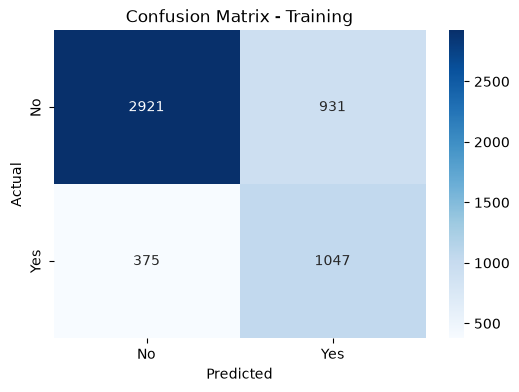

In [74]:
cm_train = confusion_matrix(y_train, y_train_pred)

print("Evaluasi Training")
print("\nConfusion Matrix:")
print(cm_train)

print("\nClassification Report:")
print(classification_report(
    y_train,
    y_train_pred,
    target_names=target_encoder.classes_
))

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title("Confusion Matrix - Training")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Yoseva Faurensia Sitohang_202431195

Evaluasi Testing

Confusion Matrix:
[[995 316]
 [118 329]]

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.76      0.82      1311
         Yes       0.51      0.74      0.60       447

    accuracy                           0.75      1758
   macro avg       0.70      0.75      0.71      1758
weighted avg       0.80      0.75      0.77      1758



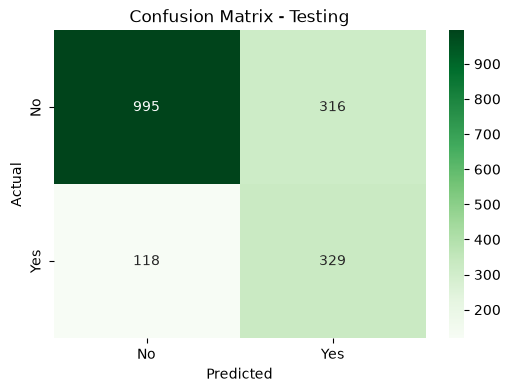

In [75]:
cm_test = confusion_matrix(y_test, y_test_pred)

print("Evaluasi Testing")
print("\nConfusion Matrix:")
print(cm_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=target_encoder.classes_
))

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title("Confusion Matrix - Testing")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Yoseva Faurensia Sitohang_202431195

In [76]:
data_baru = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 12,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "Yes",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 55.0,
    "TotalCharges": 660.0
}])

data_baru_encoded = data_baru.copy()

for col in categorical_features:
    data_baru_encoded[col] = label_encoders[col].transform(data_baru_encoded[col])

data_baru_encoded = data_baru_encoded.reindex(columns=X.columns)

hasil_prediksi = model.predict(data_baru_encoded)
hasil_label = target_encoder.inverse_transform(hasil_prediksi)

print("Hasil prediksi pelanggan baru:", hasil_label[0])

# Yoseva Faurensia Sitohang_202431195

Hasil prediksi pelanggan baru: Yes
